# Zhang data

### Data importing

In [43]:
import numpy as np
import astropy as ap
from astropy.io import ascii

filename = 'zhang_tab_4_6.csv' 
ohm_data = ascii.read(filename, format ='csv', delimiter = ';',header_start = 62, data_start =65 )
#print(ohm_data)

fname = 'zhang_tab_5_7.csv' 
non_ohm_data = ascii.read(fname, format ='csv', delimiter = ';',header_start = 62, data_start =65 )
#non_ohm_data

### Conversion to pandas dataframes

In [35]:
import pandas as pd

# 1. Convert the Astropy Tables into Pandas DataFrames
ohm_df = ohm_data.to_pandas()
non_ohm_df = non_ohm_data.to_pandas()

# 2. Combine the two Pandas DataFrames row-wise
data = pd.concat([ohm_df, non_ohm_df], ignore_index=True)

# 3. Rebuild your features array (Make sure your column names match exactly!)
features = np.column_stack((data['W1'], data['W2'], data['W3'], data['W4'])).astype(float)

# 4. Check the shape to confirm it worked!
print("The shape of my combined features array is:", features.shape)
#features
#data

The shape of my combined features array is: (378, 4)


In [36]:
# 2. THE FIX: Add the 'is_OHM' column to label them BEFORE combining
ohm_df['is_OHM'] = True
non_ohm_df['is_OHM'] = False

# 3. Combine the two datasets row-wise
data = pd.concat([ohm_df, non_ohm_df], ignore_index=True)

# 4. Drop the missing data (NaNs) so the linear algebra doesn't crash
clean_data = data.dropna(subset=['W1', 'W2', 'W3', 'W4']).copy()

# 5. Rebuild your pure mathematical features array
features = np.column_stack((clean_data['W1'], clean_data['W2'], 
                            clean_data['W3'], clean_data['W4'])).astype(float)

print("Data shape after cleaning:", clean_data.shape)
print("Features array shape:", features.shape)

Data shape after cleaning: (340, 34)
Features array shape: (340, 4)


### Adding Colour indices

In [37]:
# Add the color combinations to the combined 'data' DataFrame
data['W1-W2'] = data['W1'] - data['W2']
data['W1-W3'] = data['W1'] - data['W3']
data['W1-W4'] = data['W1'] - data['W4']
data['W2-W3'] = data['W2'] - data['W3']
data['W2-W4'] = data['W2'] - data['W4']
data['W3-W4'] = data['W3'] - data['W4']

# Do the exact same for your 'clean_data' DataFrame
clean_data['W1-W2'] = clean_data['W1'] - clean_data['W2']
clean_data['W1-W3'] = clean_data['W1'] - clean_data['W3']
clean_data['W1-W4'] = clean_data['W1'] - clean_data['W4']
clean_data['W2-W3'] = clean_data['W2'] - clean_data['W3']
clean_data['W2-W4'] = clean_data['W2'] - clean_data['W4']
clean_data['W3-W4'] = clean_data['W3'] - clean_data['W4']

# Print out a few rows to verify the columns were created properly
clean_data[['W1', 'W2', 'W3', 'W4', 'W1-W2', 'W1-W3', 'W2-W3']]
#clean_data

,W1,W2,W3,W4,W1-W2,W1-W3,W2-W3
0,12.369,12.209,7.985,3.792,0.160,4.384,4.224
1,12.376,11.228,6.502,2.875,1.148,5.874,4.726
2,5.865,5.264,0.074,-2.725,0.601,5.791,5.190
3,15.129,14.136,9.860,7.200,0.993,5.269,4.276
4,8.862,7.802,4.775,2.369,1.060,4.087,3.027
...,...,...,...,...,...,...,...
373,12.838,11.979,7.884,4.209,0.859,4.954,4.095
374,12.916,12.164,8.147,5.786,0.752,4.769,4.017
375,11.508,10.363,7.620,4.908,1.145,3.888,2.743
376,13.466,11.354,6.923,4.342,2.112,6.543,4.431


### Reproducing plots from Zhang(2014) paper

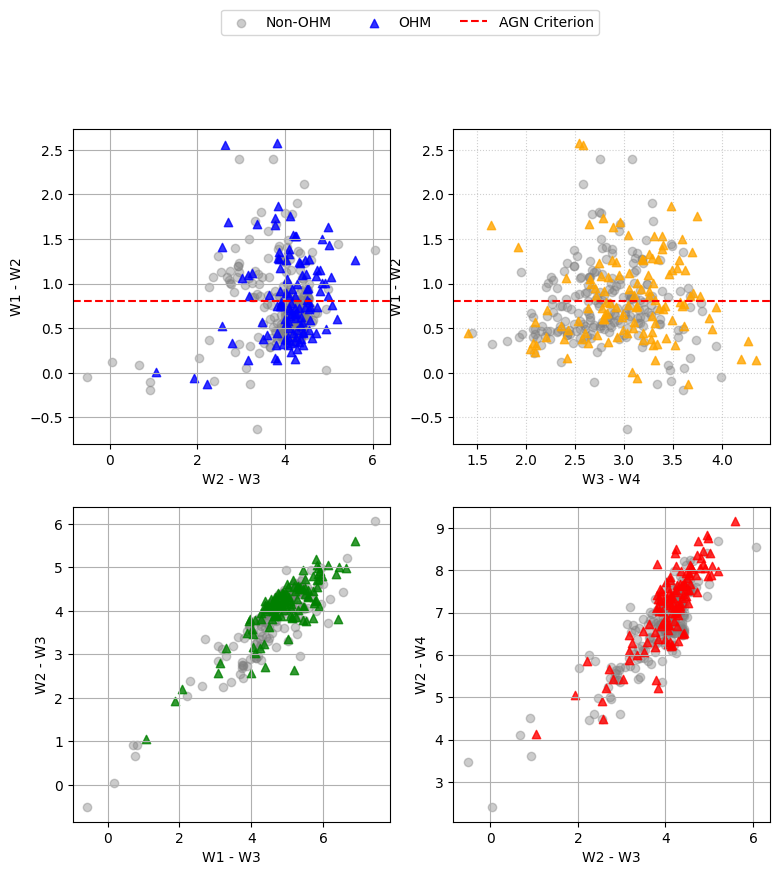

In [42]:
import matplotlib.pyplot as plt

# 1. Create masks to separate the OHM and non-OHM galaxies
ohm_mask = clean_data['is_OHM'] == True
non_ohm_mask = clean_data['is_OHM'] == False

fig, axes = plt.subplots(2, 2, figsize=(9, 9))

# --- Plot 1: W2-W3 vs W1-W2 (Figure 3 in Zhang 2014) ---
# Plot non-OHM first (gray circles)
axes[0,0].scatter(clean_data.loc[non_ohm_mask, 'W2-W3'], clean_data.loc[non_ohm_mask, 'W1-W2'], 
                  alpha=0.4, color='gray', marker='o', label='Non-OHM')
# Plot OHM on top (blue triangles)
axes[0,0].scatter(clean_data.loc[ohm_mask, 'W2-W3'], clean_data.loc[ohm_mask, 'W1-W2'], 
                  alpha=0.8, color='blue', marker='^', label='OHM')
# Add AGN Criterion line (W1-W2 > 0.8)
axes[0,0].axhline(0.8, color='red', linestyle='--', label='AGN Criterion')
axes[0,0].set_xlabel('W2 - W3')
axes[0,0].set_ylabel('W1 - W2')
axes[0,0].grid(True)

# --- Plot 2: W3-W4 vs W1-W2 ---
axes[0,1].scatter(clean_data.loc[non_ohm_mask, 'W3-W4'], clean_data.loc[non_ohm_mask, 'W1-W2'], 
                  alpha=0.4, color='gray', marker='o')
axes[0,1].scatter(clean_data.loc[ohm_mask, 'W3-W4'], clean_data.loc[ohm_mask, 'W1-W2'], 
                  alpha=0.8, color='orange', marker='^')
axes[0,1].axhline(0.8, color='red', linestyle='--')
axes[0,1].set_xlabel('W3 - W4')
axes[0,1].set_ylabel('W1 - W2')
axes[0,1].grid(True, linestyle=':', alpha=0.6)

# --- Plot 3: W1-W3 vs W2-W3 ---
axes[1,0].scatter(clean_data.loc[non_ohm_mask, 'W1-W3'], clean_data.loc[non_ohm_mask, 'W2-W3'], 
                  alpha=0.4, color='gray', marker='o')
axes[1,0].scatter(clean_data.loc[ohm_mask, 'W1-W3'], clean_data.loc[ohm_mask, 'W2-W3'], 
                  alpha=0.8, color='green', marker='^')
axes[1,0].set_xlabel('W1 - W3')
axes[1,0].set_ylabel('W2 - W3')
axes[1,0].grid(True)

# --- Plot 4: W2-W3 vs W2-W4 ---
axes[1,1].scatter(clean_data.loc[non_ohm_mask, 'W2-W3'], clean_data.loc[non_ohm_mask, 'W2-W4'], 
                  alpha=0.4, color='gray', marker='o')
axes[1,1].scatter(clean_data.loc[ohm_mask, 'W2-W3'], clean_data.loc[ohm_mask, 'W2-W4'], 
                  alpha=0.8, color='red', marker='^')
axes[1,1].set_xlabel('W2 - W3')
axes[1,1].set_ylabel('W2 - W4')
axes[1,1].grid(True)

handles, labels = axes[0,0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.02))

plt.savefig('zhang_plot.png', dpi=300, bbox_inches='tight')


plt.show()

## Machine Learning (Unsupervised)
### PCA & t-SNE

New Colors Features shape: (340, 6)


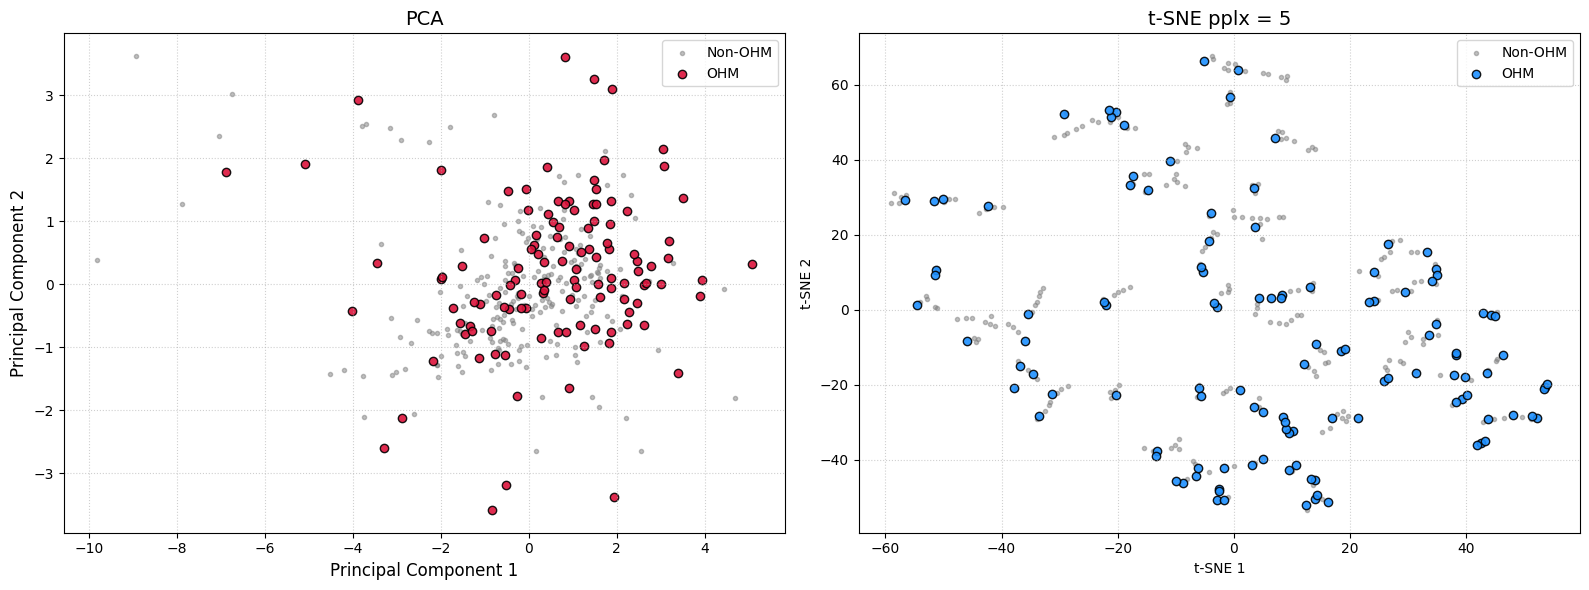

PCA Component 1 explains 64.30% of the variance.
PCA Component 2 explains 20.02% of the variance.


In [9]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# 1. Build your new features array using ALL 6 color combinations
features_colors = np.column_stack((
    clean_data['W1-W2'], 
    clean_data['W1-W3'], 
    clean_data['W1-W4'],
    clean_data['W2-W3'], 
    clean_data['W2-W4'], 
    clean_data['W3-W4']
)).astype(float)

print("New Colors Features shape:", features_colors.shape)

# 2. Standardize the colors (Mean = 0, Variance = 1)
# This is crucial so that a large difference in one color doesn't dominate the PCA
scaler_colors = StandardScaler()
features_colors_scaled = scaler_colors.fit_transform(features_colors)

# 3. RUN PCA on the colors
pca_colors = PCA(n_components=2)
pca_colors_results = pca_colors.fit_transform(features_colors_scaled)

# 4. RUN t-SNE on the colors
tsne_colors = TSNE(n_components=2, perplexity=5, random_state=42)
tsne_colors_results = tsne_colors.fit_transform(features_colors_scaled)

# 5. PLOTTING THE RESULTS
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Re-establish masks just in case
ohm_mask = clean_data['is_OHM'] == True
non_ohm_mask = clean_data['is_OHM'] == False

# ---- Plot A: PCA (Colors) ----
axes[0].scatter(pca_colors_results[non_ohm_mask, 0], pca_colors_results[non_ohm_mask, 1], 
                color='gray', alpha=0.5, label='Non-OHM', marker='.')
axes[0].scatter(pca_colors_results[ohm_mask, 0], pca_colors_results[ohm_mask, 1], 
                color='crimson', alpha=0.9, label='OHM', marker='o', edgecolor='black')
axes[0].set_title('PCA', fontsize=14)
axes[0].set_xlabel('Principal Component 1', fontsize=12)
axes[0].set_ylabel('Principal Component 2', fontsize=12)
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# ---- Plot B: t-SNE (Colors) ----
axes[1].scatter(tsne_colors_results[non_ohm_mask, 0], tsne_colors_results[non_ohm_mask, 1], 
                color='gray', alpha=0.5, label='Non-OHM', marker='.')
axes[1].scatter(tsne_colors_results[ohm_mask, 0], tsne_colors_results[ohm_mask, 1], 
                color='dodgerblue', alpha=0.9, label='OHM', marker='o', edgecolor='black')
axes[1].set_title('t-SNE pplx = 5',fontsize=14)
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Optional: Print how much variance the PCA components actually explain!
explained_variance = pca_colors.explained_variance_ratio_
print(f"PCA Component 1 explains {explained_variance[0]*100:.2f}% of the variance.")
print(f"PCA Component 2 explains {explained_variance[1]*100:.2f}% of the variance.")

### PCA, t-SNE and UMAP

/users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/tmp/ipykernel_3126828/816943578.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


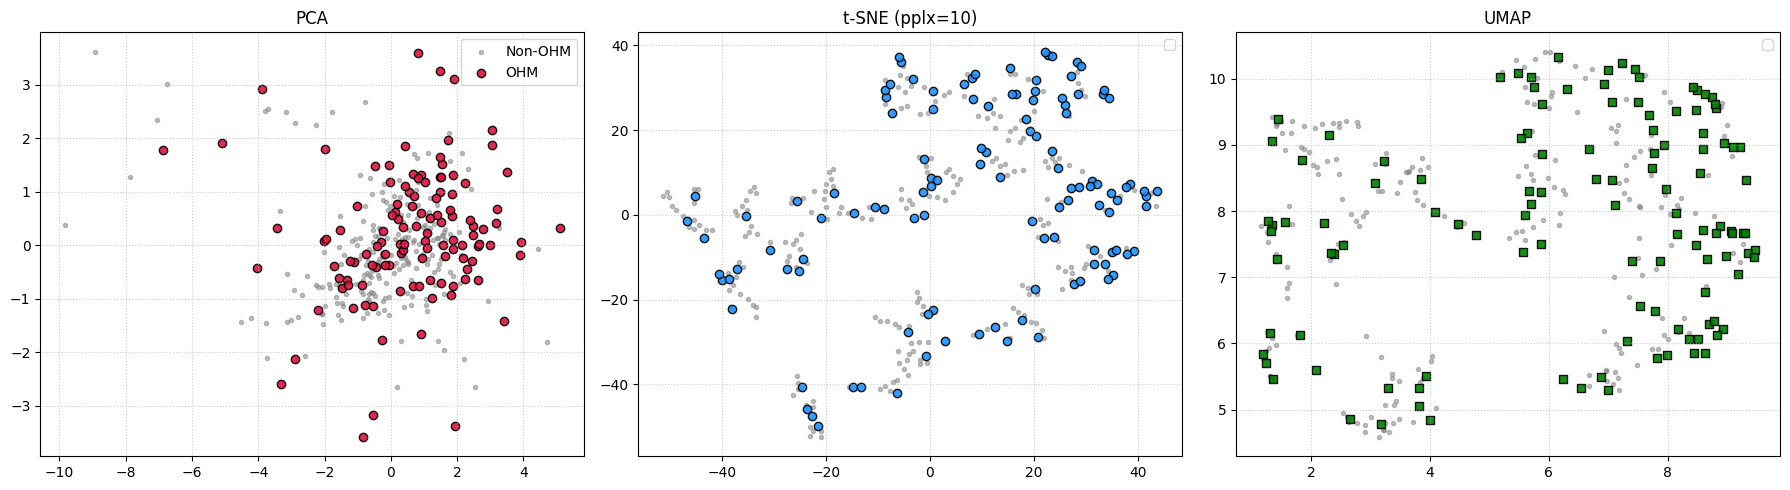

In [10]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import umap

# 1. Build features array (Ensuring variable name is consistent)
features_colors = np.column_stack((
    clean_data['W1-W2'], 
    clean_data['W1-W3'], 
    clean_data['W1-W4'],
    clean_data['W2-W3'], 
    clean_data['W2-W4'], 
    clean_data['W3-W4']
)).astype(float)

# 2. Standardize
scaler = StandardScaler()
features_colors_scaled = scaler.fit_transform(features_colors)

# 3. Run Algorithms
pca_results = PCA(n_components=2).fit_transform(features_colors_scaled)
tsne_results = TSNE(n_components=2, perplexity=10, random_state=42).fit_transform(features_colors_scaled)
reducer = umap.UMAP(n_neighbors=20, min_dist=0.1, n_components=2, random_state=42)
umap_results = reducer.fit_transform(features_colors_scaled) # Fixed the 'u' typo here

# 4. PLOTTING (Changed to 1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # Increased to 3 subplots

ohm_mask = clean_data['is_OHM'] == True
non_ohm_mask = clean_data['is_OHM'] == False

# Plot PCA
axes[0].scatter(pca_results[non_ohm_mask, 0], pca_results[non_ohm_mask, 1], color='gray', alpha=0.5, label='Non-OHM', marker='.')
axes[0].scatter(pca_results[ohm_mask, 0], pca_results[ohm_mask, 1], color='crimson', alpha=0.9, label='OHM', marker='o', edgecolor='black')
axes[0].set_title('PCA')

# Plot t-SNE
axes[1].scatter(tsne_results[non_ohm_mask, 0], tsne_results[non_ohm_mask, 1], color='gray', alpha=0.5, marker='.')
axes[1].scatter(tsne_results[ohm_mask, 0], tsne_results[ohm_mask, 1], color='dodgerblue', alpha=0.9, marker='o', edgecolor='black')
axes[1].set_title('t-SNE (pplx=10)')

# Plot UMAP (Now axes[2] is valid!)
axes[2].scatter(umap_results[non_ohm_mask, 0], umap_results[non_ohm_mask, 1], color='gray', alpha=0.5, marker='.')
axes[2].scatter(umap_results[ohm_mask, 0], umap_results[ohm_mask, 1], color='green', alpha=0.9, marker='s', edgecolor='black')
axes[2].set_title('UMAP')

for ax in axes:
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### UMAP in 3D

In [11]:
import pandas as pd
import plotly.express as px
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# 1. Define your columns and set your manual perplexity here!
color_columns = ['W1-W2', 'W1-W3', 'W1-W4', 'W2-W3', 'W2-W4', 'W3-W4']
perplexity_value = 5  # Change this number and re-run the cell to test different values

print(f"Calculating 3D t-SNE with perplexity={perplexity_value}... (Please wait)")

# 2. Extract and scale the features
features = clean_data[color_columns]
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# 3. Run t-SNE with 3 components
tsne_3d = TSNE(n_components=3, perplexity=perplexity_value, random_state=42)
tsne_results = tsne_3d.fit_transform(features_scaled)

# 4. Build a DataFrame for Plotly
plot_df = pd.DataFrame(tsne_results, columns=['tsne_1', 'tsne_2', 'tsne_3'])
plot_df['Galaxy Type'] = clean_data['is_OHM'].map({True: 'OHM', False: 'Non-OHM'}).values

# 5. Render the 3D interactive plot
fig = px.scatter_3d(
    plot_df, 
    x='tsne_1', y='tsne_2', z='tsne_3',
    color='Galaxy Type',
    color_discrete_map={'OHM': 'crimson', 'Non-OHM': 'gray'},
    title=f'3D t-SNE,colour indices (Perplexity: {perplexity_value})',
    opacity=0.8
)


fig.update_traces(marker=dict(size=4))
fig.update_layout(width=900, height=700, margin=dict(l=0, r=0, b=0, t=40))

fig.write_html("my_3d_tsne.html")
print("Plot successfully saved as 'my_3d_tsne.html'!")

Calculating 3D t-SNE with perplexity=5... (Please wait)
Plot successfully saved as 'my_3d_tsne.html'!


## Adding Spectral Indices

In [13]:
# 1. Extract the spectral index features 
spectral_cols = ['alf21', 'alf32', 'alf43','alf41'] 
clean_2data= clean_data.dropna(subset = spectral_cols)

spec_feats = clean_2data[spectral_cols].values
#spec_feats
scaler = StandardScaler()
feats_scaled = scaler.fit_transform(spec_feats)

## Machine learning (Unsupervised)

In [14]:
import umap

# 1. Initialize UMAP
# n_neighbors: low values focus on local structure, high values on global
# min_dist: how tightly UMAP packs points together
reducer = umap.UMAP(n_neighbors=20, 
                    min_dist=0.01, 
                    n_components=2, 
                    random_state=42)

# 2. Run UMAP on your scaled spectral indices
umap_results = reducer.fit_transform(feats_scaled)

print("UMAP reduction complete.")

/users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP reduction complete.


IndexError: boolean index did not match indexed array along axis 0; size of axis is 305 but size of corresponding boolean axis is 340

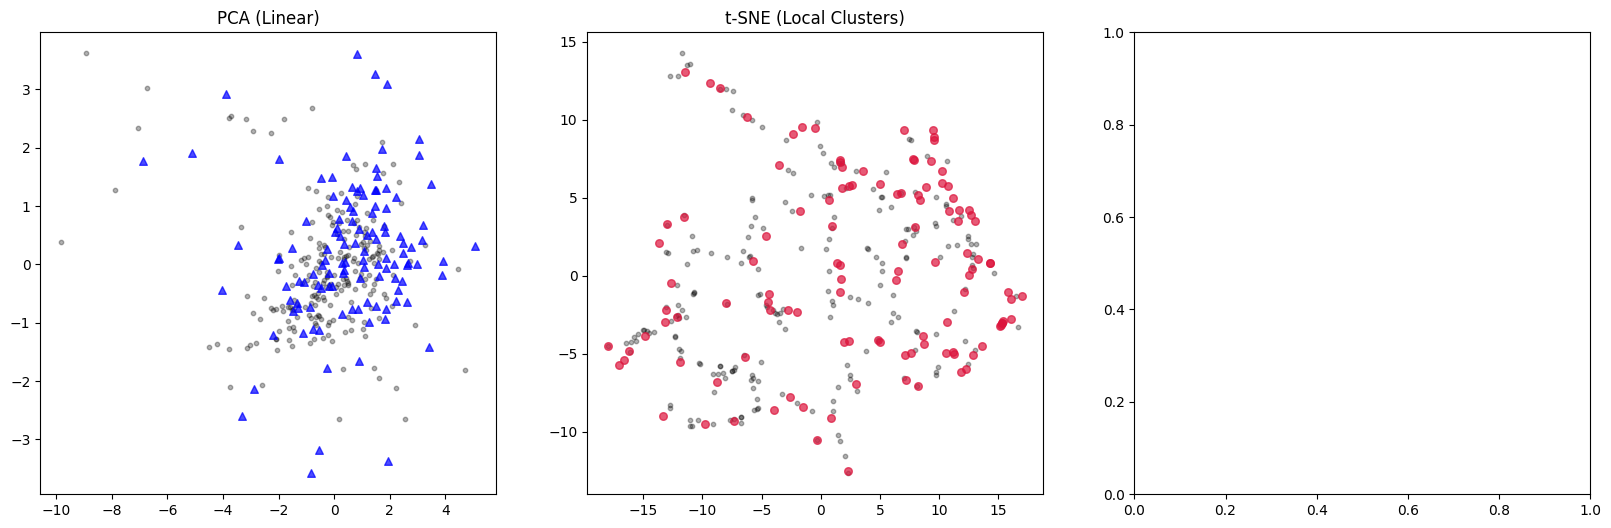

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Plot PCA
axes[0].scatter(pca_results[non_ohm_mask, 0], pca_results[non_ohm_mask, 1], c='black', alpha=0.3, s=10, label='Non-OHM')
axes[0].scatter(pca_results[ohm_mask, 0], pca_results[ohm_mask, 1], c='blue', alpha=0.7, s=30, marker='^', label='OHM')
axes[0].set_title('PCA (Linear)')

# Plot t-SNE
axes[1].scatter(tsne_results[non_ohm_mask, 0], tsne_results[non_ohm_mask, 1], c='black', alpha=0.3, s=10)
axes[1].scatter(tsne_results[ohm_mask, 0], tsne_results[ohm_mask, 1], c='crimson', alpha=0.7, s=30, marker='o')
axes[1].set_title('t-SNE (Local Clusters)')

# Plot UMAP
axes[2].scatter(umap_results[non_ohm_mask, 0], umap_results[non_ohm_mask, 1], c='black', alpha=0.3, s=10)
axes[2].scatter(umap_results[ohm_mask, 0], umap_results[ohm_mask, 1], c='green', alpha=0.7, s=30, marker='s')
axes[2].set_title('UMAP (Local & Global)')

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

## All 17 features

In [16]:
# --- THE FIX: Define all the base columns we need and drop ANY missing data ---
base_columns_needed = [
    'W1', 'W2', 'W3', 'W4', 
    'alf21', 'alf32', 'alf43', 'alf41', 
    'logLW1', 'logLW2', 'logLW3', 'logLW4', 
    'Dr'
]
# Overwrite clean_data to ensure absolutely no NaNs exist in these specific columns
clean_data = clean_data.dropna(subset=base_columns_needed).copy()

# --- RE-DEFINE MASKS (Crucial!) ---
# Because we just dropped some rows, we must update the masks so the lengths match for plotting later
ohm_mask = clean_data['is_OHM'] == True
non_ohm_mask = clean_data['is_OHM'] == False


# 1. Create the Color Indices (Now perfectly clean)
clean_data['W1-W2'] = clean_data['W1'] - clean_data['W2']
clean_data['W2-W3'] = clean_data['W2'] - clean_data['W3']
clean_data['W3-W4'] = clean_data['W3'] - clean_data['W4']
clean_data['W1-W4'] = clean_data['W1'] - clean_data['W4']

# 2. Build the Master Feature Matrix
features_master = np.column_stack((
    # 1. Raw Brightness (4)
    clean_data['W1'], clean_data['W2'], clean_data['W3'], clean_data['W4'],
    
    # 2. Color Indices (4)
    clean_data['W1-W2'], clean_data['W2-W3'], clean_data['W3-W4'], clean_data['W1-W4'],
    
    # 3. Spectral Indices (4)
    clean_data['alf21'], clean_data['alf32'], clean_data['alf43'], clean_data['alf41'],
    
    # 4. Physical Luminosities (4)
    clean_data['logLW1'], clean_data['logLW2'], clean_data['logLW3'], clean_data['logLW4'],
    
    # 5. Distance (1)
    clean_data['Dr']
)).astype(float)

print("Master Features shape after final cleaning:", features_master.shape)

# 3. Standardize the High-Dimensional Data 
scaler = StandardScaler()
features_master_scaled = scaler.fit_transform(features_master)

# 4. Run Dimensionality Reduction Algorithms
print("Running PCA...")
pca = PCA(n_components=2)
pca_results = pca.fit_transform(features_master_scaled)

print("Running t-SNE...")
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_results = tsne.fit_transform(features_master_scaled)

print("Running UMAP...")
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
umap_results = reducer.fit_transform(features_master_scaled)

print("All algorithms complete! Ready to plot.")

Master Features shape after final cleaning: (305, 17)
Running PCA...
Running t-SNE...
Running UMAP...


/users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


All algorithms complete! Ready to plot.


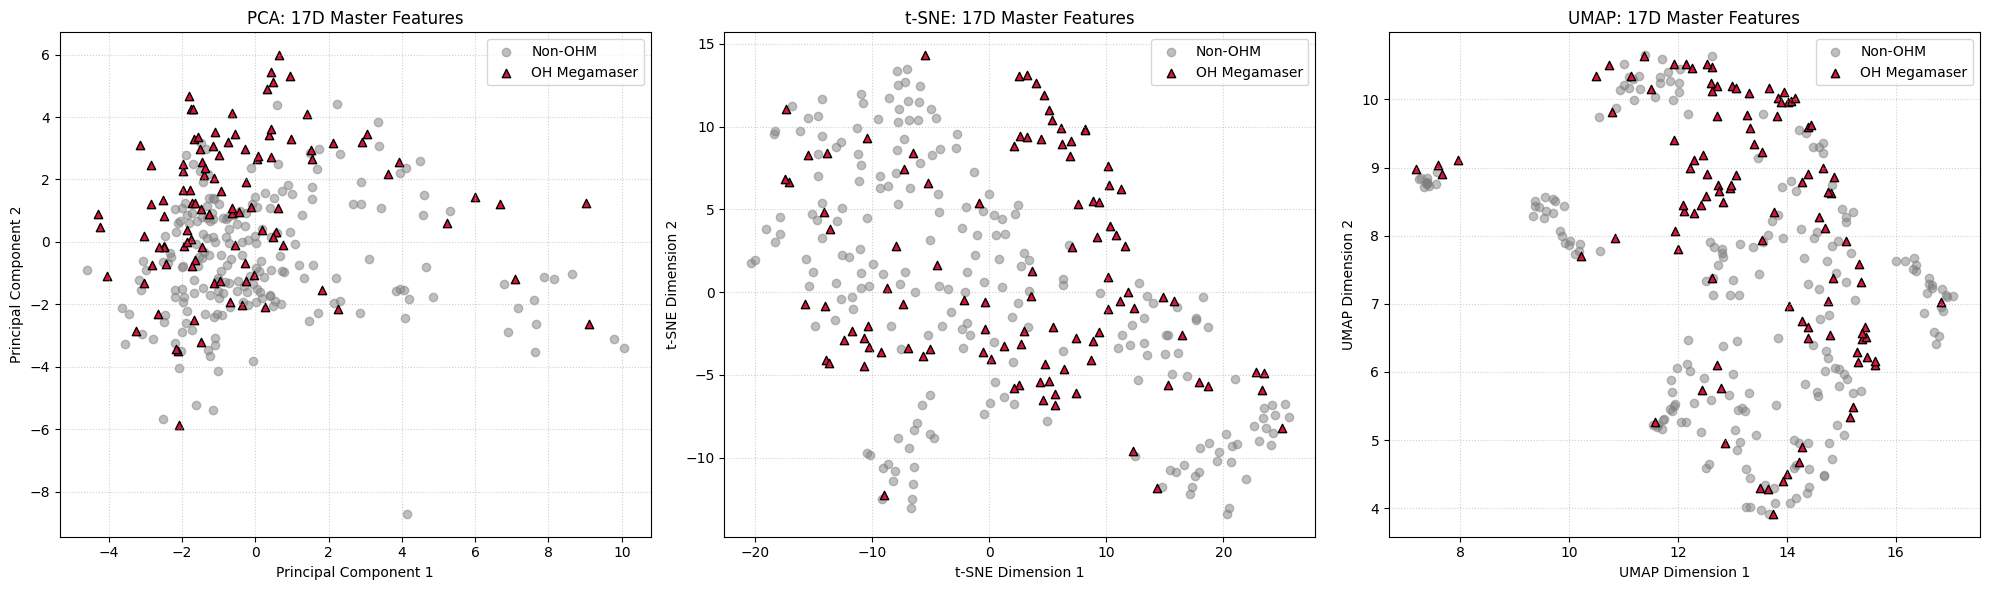

In [17]:
# 1. Define the True/False Masks for plotting
ohm_mask = clean_data['is_OHM'] == True
non_ohm_mask = clean_data['is_OHM'] == False

# 2. Set up a 1x3 Figure layout (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# ---- PLOT 1: PCA ----
axes[0].scatter(pca_results[non_ohm_mask, 0], pca_results[non_ohm_mask, 1], 
                color='gray', alpha=0.5, label='Non-OHM')
axes[0].scatter(pca_results[ohm_mask, 0], pca_results[ohm_mask, 1], 
                color='crimson', marker='^', edgecolor='black', label='OH Megamaser')
axes[0].set_title('PCA: 17D Master Features')
axes[0].set_xlabel('Principal Component 1')
axes[0].set_ylabel('Principal Component 2')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# ---- PLOT 2: t-SNE ----
axes[1].scatter(tsne_results[non_ohm_mask, 0], tsne_results[non_ohm_mask, 1], 
                color='gray', alpha=0.5, label='Non-OHM')
axes[1].scatter(tsne_results[ohm_mask, 0], tsne_results[ohm_mask, 1], 
                color='crimson', marker='^', edgecolor='black', label='OH Megamaser')
axes[1].set_title('t-SNE: 17D Master Features')
axes[1].set_xlabel('t-SNE Dimension 1')
axes[1].set_ylabel('t-SNE Dimension 2')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

# ---- PLOT 3: UMAP ----
axes[2].scatter(umap_results[non_ohm_mask, 0], umap_results[non_ohm_mask, 1], 
                color='gray', alpha=0.5, label='Non-OHM')
axes[2].scatter(umap_results[ohm_mask, 0], umap_results[ohm_mask, 1], 
                color='crimson', marker='^', edgecolor='black', label='OH Megamaser')
axes[2].set_title('UMAP: 17D Master Features')
axes[2].set_xlabel('UMAP Dimension 1')
axes[2].set_ylabel('UMAP Dimension 2')
axes[2].legend()
axes[2].grid(True, linestyle=':', alpha=0.6)

# Make it look clean and display it
plt.tight_layout()
plt.show()

## 3d Plot of t-SNE and UMAP

In [19]:
# 3D UMAP with tight clustering hyperparameters
umap_3d = umap.UMAP(
    n_components=3, 
    n_neighbors=10,     # Focus heavily on local neighborhoods
    min_dist=0.01,      # Pack points extremely tightly
    random_state=42
)
umap_3d_results = umap_3d.fit_transform(features_master_scaled)

# 3D t-SNE with exaggerated separation hyperparameters
tsne_3d = TSNE(
    n_components=3, 
    perplexity=45,          # Slightly larger view of the neighborhood
    early_exaggeration=24,  # Force more blank space between clusters
    random_state=42
)
tsne_3d_results = tsne_3d.fit_transform(features_master_scaled)

# Add the 3D coordinates back into your clean dataframe for Plotly to use
clean_data['UMAP_X'] = umap_3d_results[:, 0]
clean_data['UMAP_Y'] = umap_3d_results[:, 1]
clean_data['UMAP_Z'] = umap_3d_results[:, 2]

clean_data['tSNE_X'] = tsne_3d_results[:, 0]
clean_data['tSNE_Y'] = tsne_3d_results[:, 1]
clean_data['tSNE_Z'] = tsne_3d_results[:, 2]

# Create a clean string column for the legend
clean_data['Galaxy_Class'] = clean_data['is_OHM'].map({True: 'OH Megamaser', False: 'Non-OHM'})

# ==========================================
# PLOT 1: Interactive 3D UMAP
# ==========================================
fig_umap = px.scatter_3d(
    clean_data, 
    x='UMAP_X', y='UMAP_Y', z='UMAP_Z',
    color='Galaxy_Class',
    color_discrete_map={'OH Megamaser': 'red', 'Non-OHM': 'lightgray'},
    opacity=0.8,
    title='3D UMAP: 17D Physics Master Array (Tuned Clustering)'
)
# Make the dots a bit smaller for better 3D viewing
fig_umap.update_traces(marker=dict(size=4))
fig_umap.write_html('3D_UMAP_Tuned.html')
print("Saved '3D_UMAP_Tuned.html' to your file browser!")

# ==========================================
# PLOT 2: Interactive 3D t-SNE
# ==========================================
fig_tsne = px.scatter_3d(
    clean_data, 
    x='tSNE_X', y='tSNE_Y', z='tSNE_Z',
    color='Galaxy_Class',
    color_discrete_map={'OH Megamaser': 'red', 'Non-OHM': 'lightgray'},
    opacity=0.8,
    title='3D t-SNE: 17D Physics Master Array (Tuned Clustering)'
)
fig_tsne.update_traces(marker=dict(size=4))
fig_tsne.write_html('3D_tSNE_Tuned.html')
print("Saved '3D_tSNE_Tuned.html' to your file browser!")

/users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Saved '3D_UMAP_Tuned.html' to your file browser!
Saved '3D_tSNE_Tuned.html' to your file browser!


## Machine learning (Supervised)
### All features

### Random forest Classifier

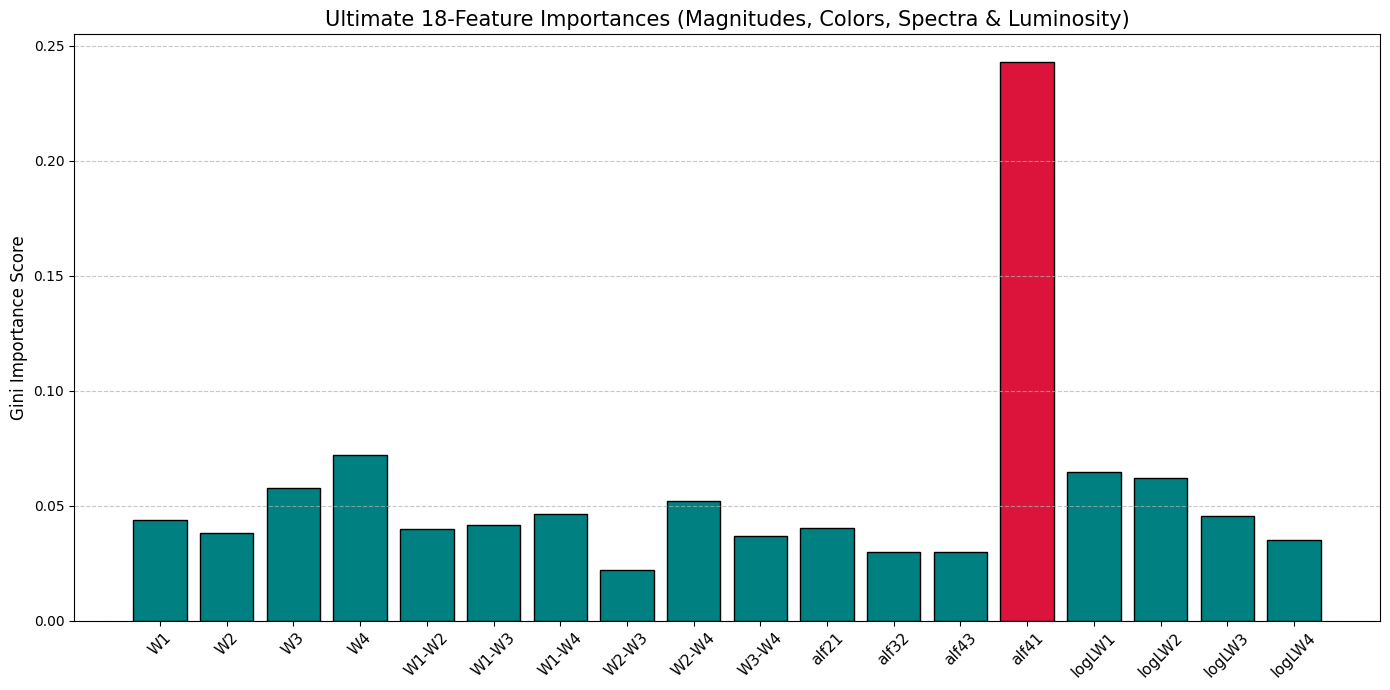

The most important distinguishing physical trait is: alf41


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# ==========================================
# STEP 1: CALCULATE LOGARITHMIC LUMINOSITIES
# ==========================================
# 1a. Calculate Distance Modulus (assuming 'Dist' is in Megaparsecs)
clean_data['Dr'] = 5 * np.log10(clean_data['Dr'] * 1e6) - 5

# 1b. Calculate Absolute Magnitudes (M = m - Distance Modulus)
clean_data['M_W1'] = clean_data['W1'] - clean_data['Dr']
clean_data['M_W2'] = clean_data['W2'] - clean_data['Dr']
clean_data['M_W3'] = clean_data['W3'] - clean_data['Dr']
clean_data['M_W4'] = clean_data['W4'] - clean_data['Dr']

# 1c. Convert to Logarithmic Luminosities (Solar Units)
# The math simplifies elegantly: log(L) = -0.4 * (M_galaxy - M_sun)
# Approximate Solar absolute magnitudes in WISE bands: W1 ~ 3.24, W2 ~ 3.27, W3 ~ 3.23, W4 ~ 3.25
clean_data['logLW1'] = -0.4 * (clean_data['M_W1'] - 3.24)
clean_data['logLW2'] = -0.4 * (clean_data['M_W2'] - 3.27)
clean_data['logLW3'] = -0.4 * (clean_data['M_W3'] - 3.23)
clean_data['logLW4'] = -0.4 * (clean_data['M_W4'] - 3.25)

# ==========================================
# STEP 2: BUILD THE 18-FEATURE MASTER MATRIX
# ==========================================
master_columns_18 = [
    'W1', 'W2', 'W3', 'W4',                                  # Base Magnitudes (4)
    'W1-W2', 'W1-W3', 'W1-W4', 'W2-W3', 'W2-W4', 'W3-W4',    # Color Indices (6)
    'alf21', 'alf32', 'alf43', 'alf41',                      # Spectral Indices (4)
    'logLW1', 'logLW2', 'logLW3', 'logLW4'                   # Log Luminosities (4)
]

# Drop any rows missing data across these 18 features + the label
rf_clean = clean_data.dropna(subset=master_columns_18 + ['is_OHM']).copy()

# Set up features (X) and labels (y)
X = rf_clean[master_columns_18].values
y = rf_clean['is_OHM'].astype(int)

# Standardize the data (CRITICAL for mixed units!)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==========================================
# STEP 3: RUN RANDOM FOREST & PLOT RESULTS
# ==========================================
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_scaled, y)

# Extract importances
importances = rf_model.feature_importances_

# Plotting the Bar Chart
plt.figure(figsize=(14, 7))
bars = plt.bar(master_columns_18, importances, color='teal', edgecolor='black')

# Automatically highlight the absolute most important feature in Crimson
tallest_idx = np.argmax(importances)
bars[tallest_idx].set_color('crimson')
bars[tallest_idx].set_edgecolor('black')

plt.title('Ultimate 18-Feature Importances (Magnitudes, Colors, Spectra & Luminosity)', fontsize=15)
plt.ylabel('Gini Importance Score', fontsize=12)
plt.xticks(rotation=45, fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Save for your LaTeX report!
plt.savefig('Master_Feature_Importances.png', dpi=300)
plt.show()

print(f"The most important distinguishing physical trait is: {master_columns_18[tallest_idx]}")

### L1 - Lasso Regression

In [22]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# 1. Define your 14 master features
master_columns = [
    'W1', 'W2', 'W3', 'W4',                                      # Base Magnitudes
    'W1-W2', 'W1-W3', 'W1-W4', 'W2-W3', 'W2-W4', 'W3-W4',        # Color Indices
    'alf21', 'alf32', 'alf43', 'alf41'                           # Spectral Indices
]

# 2. Calculate the color indices directly in your original 'data' DataFrame BEFORE dropping NaNs
data['W1-W2'] = data['W1'] - data['W2']
data['W1-W3'] = data['W1'] - data['W3']
data['W1-W4'] = data['W1'] - data['W4']
data['W2-W3'] = data['W2'] - data['W3']
data['W2-W4'] = data['W2'] - data['W4']
data['W3-W4'] = data['W3'] - data['W4']

# 3. THE FIX: Drop any rows that are missing data across ALL 14 columns
clean_data = data.dropna(subset=master_columns).copy()

# 4. Build your feature array and scale it
features = clean_data[master_columns].values.astype(float)
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# 5. Run Lasso (L1 Regularized Logistic Regression)
lasso_classifier = LogisticRegression(penalty='l1', solver='liblinear', random_state=42)
lasso_classifier.fit(features_scaled, clean_data['is_OHM'])

# 6. Extract and print the coefficients
coefficients = lasso_classifier.coef_[0]

print("--- LASSO FEATURE SELECTION ---")
for name, coef in zip(master_columns, coefficients):
    if coef != 0:
        print(f"Kept {name}: Weight = {coef:.4f}")
    else:
        print(f"Dropped {name}: Weight = 0")

--- LASSO FEATURE SELECTION ---
Kept W1: Weight = -0.5943
Dropped W2: Weight = 0
Dropped W3: Weight = 0
Dropped W4: Weight = 0
Kept W1-W2: Weight = -0.3210
Dropped W1-W3: Weight = 0
Kept W1-W4: Weight = -8.6669
Dropped W2-W3: Weight = 0
Dropped W2-W4: Weight = 0
Dropped W3-W4: Weight = 0
Kept alf21: Weight = -0.2326
Dropped alf32: Weight = 0
Dropped alf43: Weight = 0
Kept alf41: Weight = 11.4411


/users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/users/jraghoo42/hons/hons_env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


### Some statistical analysis

Generating cross-validated predictions for the confusion matrix...


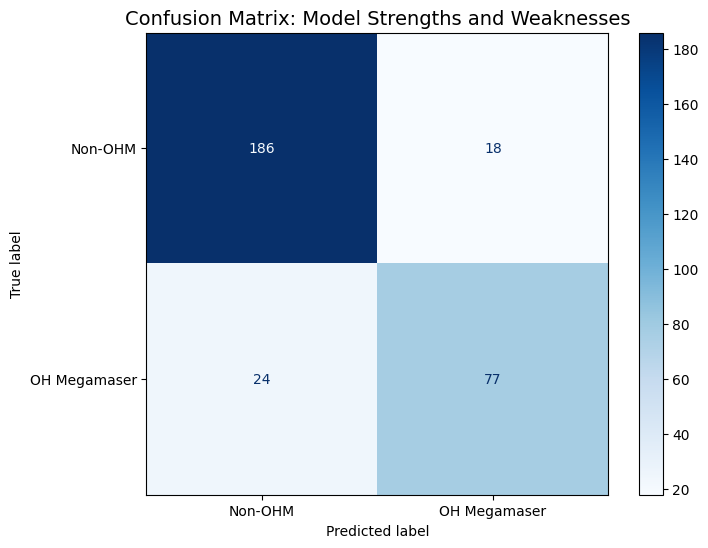

In [25]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

# 1. Create a "Pipeline" (This safely scales the data inside the CV loop automatically!)
rf_pipeline = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42))

# 2. Get a robust prediction for every single galaxy using 5-Fold CV
print("Generating cross-validated predictions for the confusion matrix...")
cv_predictions = cross_val_predict(rf_pipeline, X, y, cv=5)

# 3. Generate the mathematical matrix
cm = confusion_matrix(y, cv_predictions)

# 4. Plot it beautifully
fig, ax = plt.subplots(figsize=(8, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-OHM', 'OH Megamaser'])
disp.plot(cmap='Blues', ax=ax, values_format='d') # 'd' formats the numbers as standard integers

plt.title('Confusion Matrix: Model Strengths and Weaknesses', fontsize=14)
plt.show()

--- Model Evaluation Metrics ---
Recall:   0.550
F1 Score: 0.688
F2 Score: 0.598
ROC AUC:  0.901


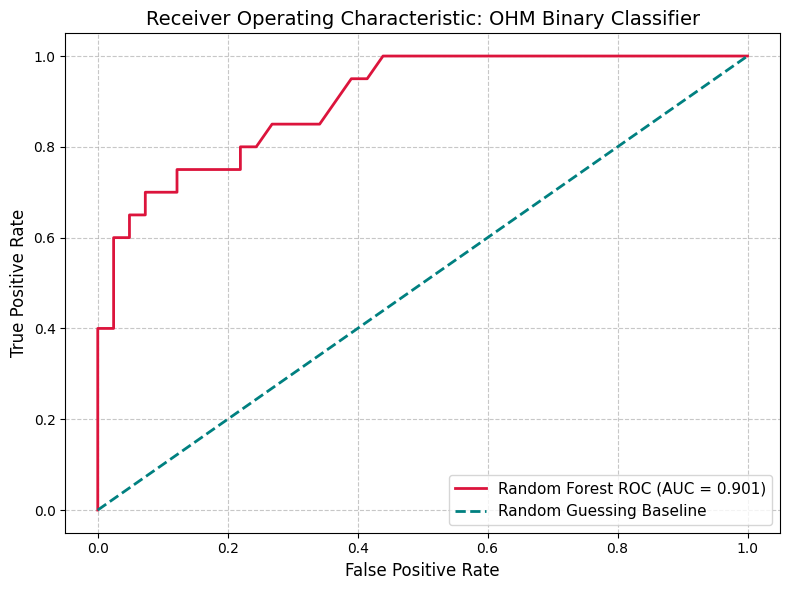

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import recall_score, f1_score, fbeta_score, roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Assuming X (features) and y (is_OHM labels) are already defined 

# 1. Perform the 80-20 Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Build and Train the Pipeline
# Using class_weight='balanced' helps the forest handle the severe target imbalance
pipeline = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'))
pipeline.fit(X_train, y_train)

# 3. Generate Predictions and Probabilities
y_pred = pipeline.predict(X_test)
y_prob = pipeline.predict_proba(X_test)[:, 1] # Probabilities of being an OHM

# 4. Calculate the Essential Metrics
model_recall = recall_score(y_test, y_pred)
model_f1 = f1_score(y_test, y_pred)
model_f2 = fbeta_score(y_test, y_pred, beta=2) # Weighs recall twice as high as precision
model_auc = roc_auc_score(y_test, y_prob)

print("--- Model Evaluation Metrics ---")
print(f"Recall:   {model_recall:.3f}")
print(f"F1 Score: {model_f1:.3f}")
print(f"F2 Score: {model_f2:.3f}")
print(f"ROC AUC:  {model_auc:.3f}")

# 5. Calculate and Plot the ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='crimson', lw=2, label=f'Random Forest ROC (AUC = {model_auc:.3f})')
plt.plot([0, 1], [0, 1], color='teal', lw=2, linestyle='--', label='Random Guessing Baseline')
plt.title('Receiver Operating Characteristic: OHM Binary Classifier', fontsize=14)
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Some Error analysis

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 1. Recreate the train/test split and get predictions
df_train, df_test = train_test_split(clean_data, test_size=0.2, random_state=42, stratify=clean_data['is_OHM'])
selected_features = ['W1', 'W1-W2', 'W1-W4', 'alf21', 'alf41']
X_test_df = df_test[selected_features].values.astype(float)

results_df = df_test.copy()
results_df['Predicted_OHM'] = final_rf.predict(X_test_df).astype(bool)
results_df['Actual_OHM'] = df_test['is_OHM']

# 2. Split test set into Correctly Classified vs. Misclassified
correctly_classified = results_df[results_df['Predicted_OHM'] == results_df['Actual_OHM']]
misclassified = results_df[results_df['Predicted_OHM'] != results_df['Actual_OHM']]

# 3. Print out statistical summary comparisons for e_W4
print("--- STATISTICAL COMPARISON OF W4 ERRORS (e_W4) ---")
print(f"Correctly Classified (n={len(correctly_classified)}):")
print(f"  Mean e_W4:   {correctly_classified['e_W4'].mean():.4f}")
print(f"  Median e_W4: {correctly_classified['e_W4'].median():.4f}")
print(f"  Max e_W4:    {correctly_classified['e_W4'].max():.4f}\n")

print(f"Misclassified Outliers (n={len(misclassified)}):")
print(f"  Mean e_W4:   {misclassified['e_W4'].mean():.4f}")
print(f"  Median e_W4: {misclassified['e_W4'].median():.4f}")
print(f"  Max e_W4:    {misclassified['e_W4'].max():.4f}")

# 4. Plot a comparison histogram to visualize the difference
plt.figure(figsize=(8, 5))
plt.hist(correctly_classified['e_W4'].dropna(), bins=20, alpha=0.6, label='Correctly Classified', color='teal', density=True)
plt.hist(misclassified['e_W4'].dropna(), bins=5, alpha=0.8, label='Misclassified Outliers', color='crimson', density=True)

plt.xlabel('W4 Photometric Error (e_W4)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.title('Error Distribution: Correct vs. Misclassified Galaxies', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

NameError: name 'final_rf' is not defined